### Comparison between SteadierCom and experimental results

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sys
sys.path.append("../functions/")
import compare_inter_exp_sim.guillen2021 as guillen2021
import compare_inter_exp_sim.correlation as correlation
import compare_inter_exp_sim.diagnostic as diagnostic

In [16]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Mapping names to seed ids (seem to have a good overlap)

Interactions were found in table (areaThreshold2.mat) from Guillen github repo: https://github.com/Mitchell-SysBio/2021_cellsystems/tree/v1.0.0

This was converted to csv in Matlab (../data/Guillen2021/Guillen_interaction.csv).

In [87]:
signal_exp = guillen2021.load_experimental_results()

In [18]:
simulation_dict = guillen2021.load_simulation_results()

/var/folders/mc/1rm74nkd4s78l46281nyt5wm0000gn/T/ipykernel_25565/141890771.py:1: FutureWarning: 

`shade` is now deprecated in favor of `fill`; setting `fill=True`.
This will become an error in seaborn v0.14.0; please update your code.

  ax = sns.kdeplot(signal_exp,shade=True,cut=0)


Text(0.5, 0, 'gLV coefficient')

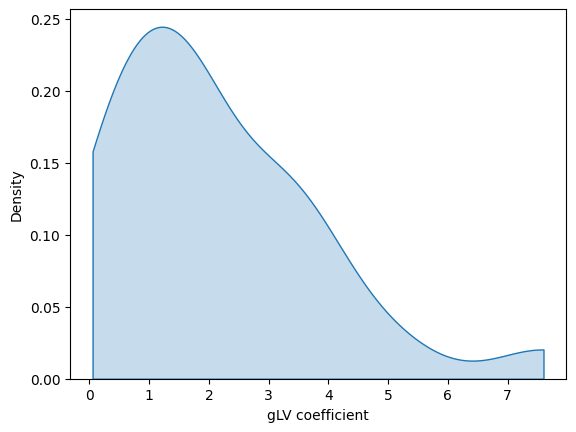

In [20]:
ax = sns.kdeplot(signal_exp,shade=True,cut=0)
ax.set_xlabel("gLV coefficient")

In [97]:
results_corr_df,results_corr_member_df = guillen2021.find_correlations(simulation_dict,signal_exp)

steadycom
steadiercom
steadiercom
smetana


In [99]:
results_corr_df_bh = results_corr_df.copy()
results_corr_df_bh["rank"] = results_corr_df_bh["p-value"].rank()
results_corr_df_bh["p-value BH critical"] = (results_corr_df_bh["rank"]/results_corr_df_bh.shape[0])*0.05

results_corr_df_bh["pass BH test"] = results_corr_df_bh["p-value"]<results_corr_df_bh["p-value BH critical"]

results_corr_df_bh.sort_values("p-value",ascending=True)

r  \
coop_or_comp simulation_method condition                              metric                          
coop         steadiercom       SteadierCom - Fixed growth             frequency            0.286912   
coop-comp    steadiercom       SteadierCom - Fixed growth             frequency            0.206953   
coop         smetana           SMETANA                                scs                  0.197574   
             steadycom         SteadyCom - Nothing fixed              rate?                0.298142   
coop-comp    steadycom         SteadyCom - Nothing fixed              rate?                0.298142   
             smetana           SMETANA                                scs                  0.078559   
             steadiercom       SteadierCom - Fixed growth             frequency*mass_rate -0.072904   
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate -0.070552   
             steadycom         SteadyCom - Fixed abundance            rate?                0.070552   
coop-comp    steadycom         SteadyCom - Fixed abundance            rate?                0.061145   
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate  0.054090   
                                                                      frequency            0.042331   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate -0.032924   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.032924   
                                                                      frequency            0.030573   
                               SteadierCom - Fixed abundance          frequency           -0.014110   
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate -0.009407   
                                                                      frequency           -0.002352   

                                                                                            p-value  \
coop_or_comp simulation_method condition                              metric                          
coop         steadiercom       SteadierCom - Fixed growth             frequency            0.008107   
coop-comp    steadiercom       SteadierCom - Fixed growth             frequency            0.056167   
coop         smetana           SMETANA                                scs                  0.140526   
             steadycom         SteadyCom - Nothing fixed              rate?                0.426777   
coop-comp    steadycom         SteadyCom - Nothing fixed              rate?                0.426777   
             smetana           SMETANA                                scs                  0.478608   
             steadiercom       SteadierCom - Fixed growth             frequency*mass_rate  0.501107   
coop         steadiercom       SteadierCom - Fixed growth             frequency*mass_rate  0.515016   
             steadycom         SteadyCom - Fixed abundance            rate?                0.515016   
coop-comp    steadycom         SteadyCom - Fixed abundance            rate?                0.572590   
coop         steadiercom       SteadierCom - Fixed growth & abundance frequency*mass_rate  0.617684   
                                                                      frequency            0.696072   
coop-comp    steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.761264   
                               SteadierCom - Fixed growth & abundance frequency*mass_rate  0.761264   
                                                                      frequency            0.777851   
                               SteadierCom - Fixed abundance          frequency            0.896401   
coop         steadiercom       SteadierCom - Fixed abundance          frequency*mass_rate  0.930826   
                                                                      frequency 

#### SteadierCom - scatterplot 

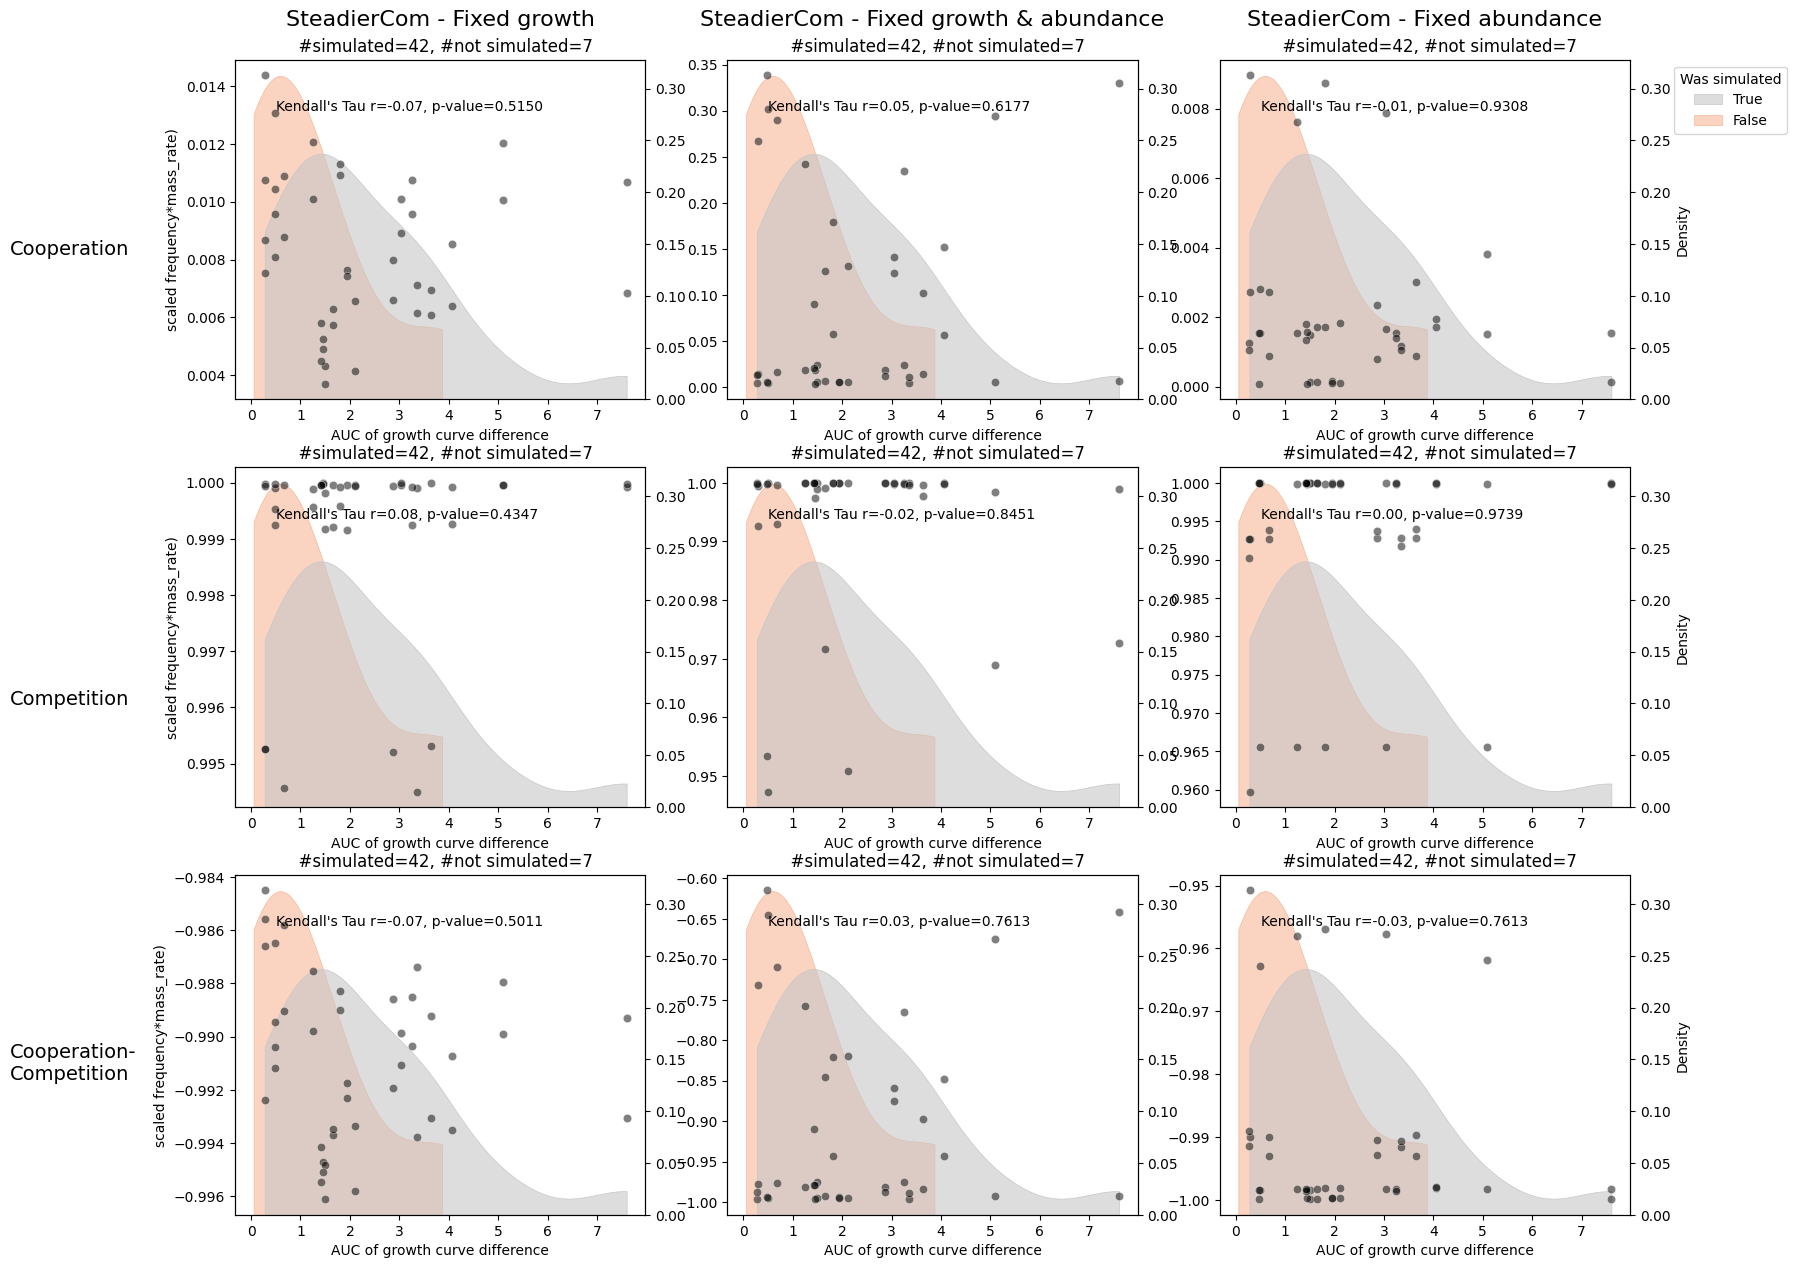

In [102]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadiercom",
                                                                                 metric="frequency*mass_rate",
                                                                                 xlabel="AUC of growth curve difference")

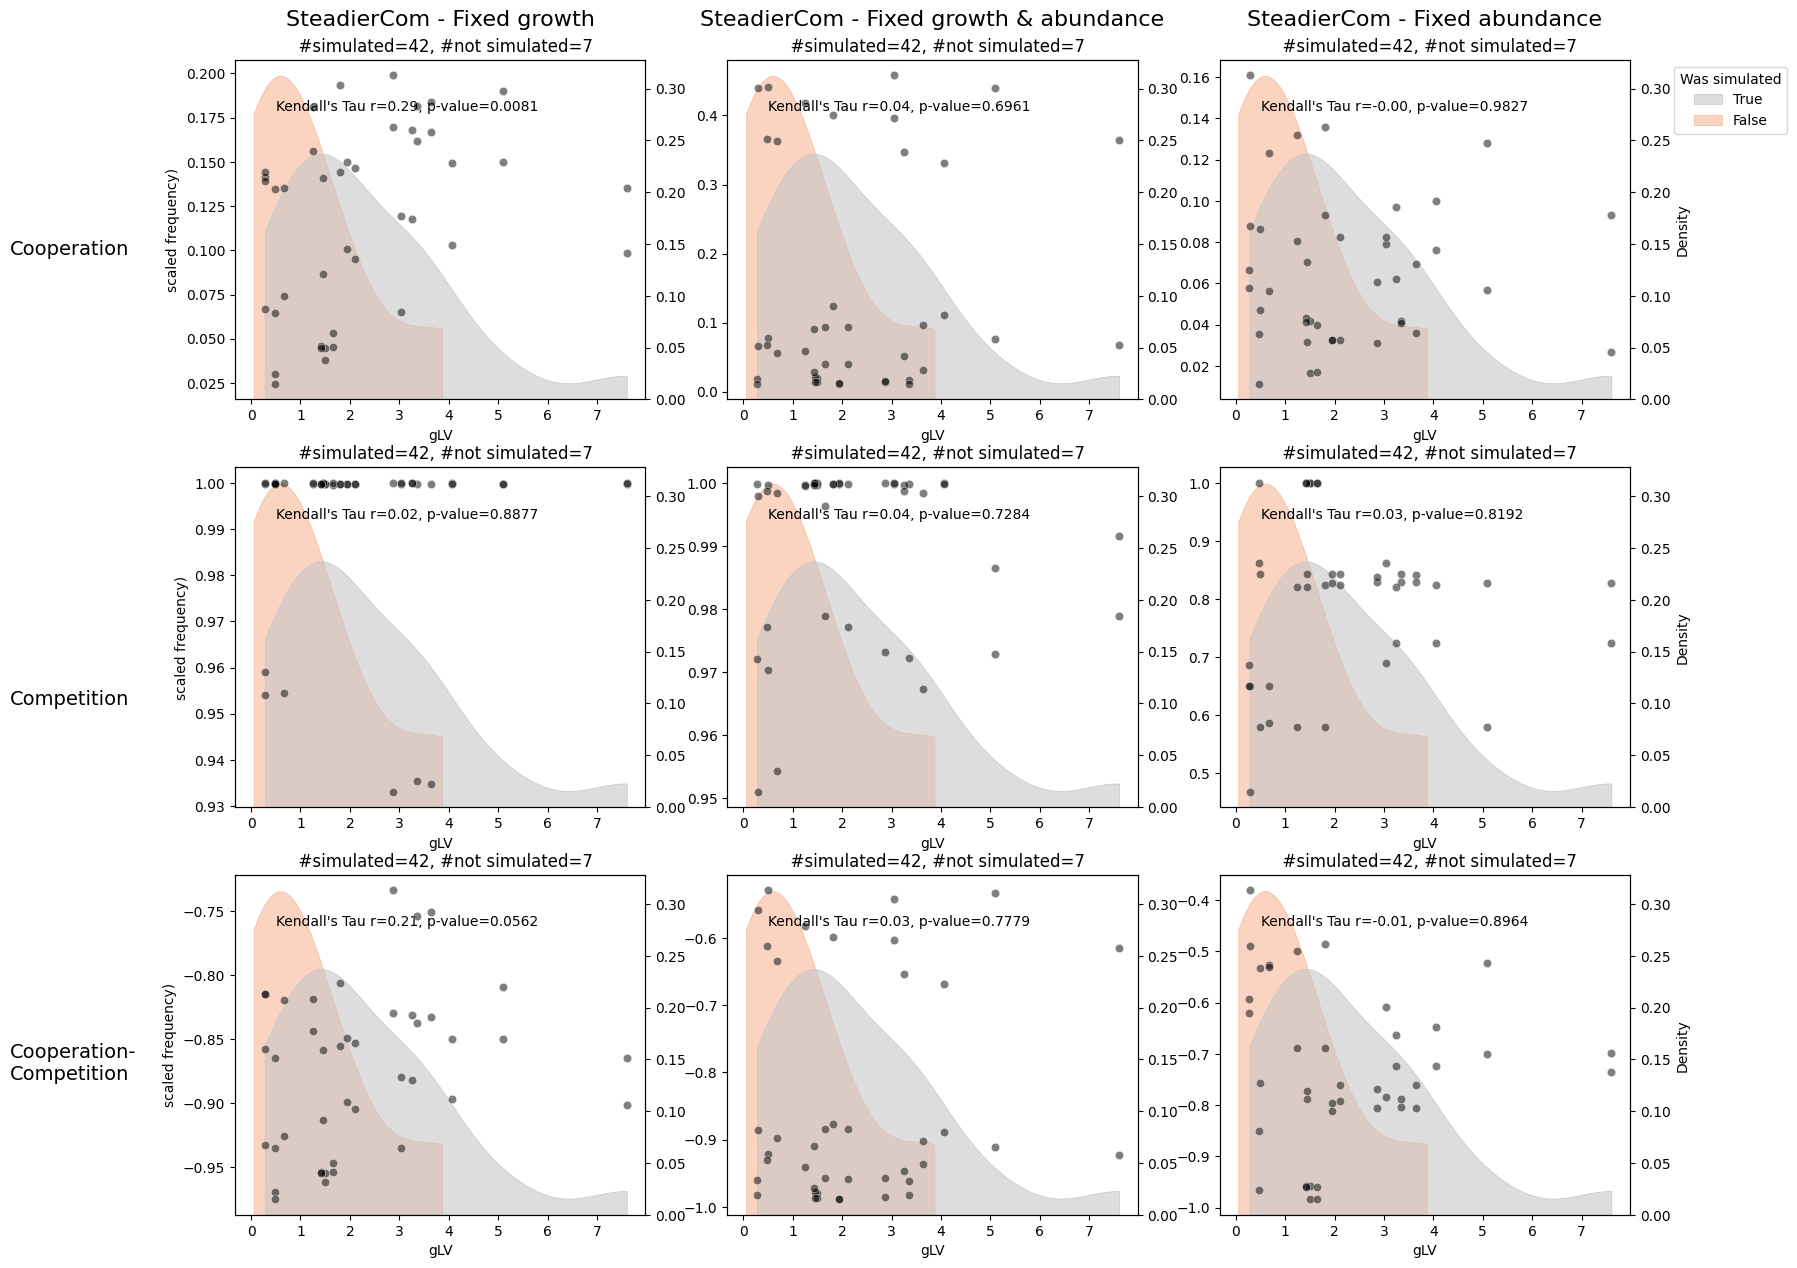

In [ ]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadiercom",
                                                                                 metric="frequency",
                                                                                xlabel="AUC of growth curve difference")

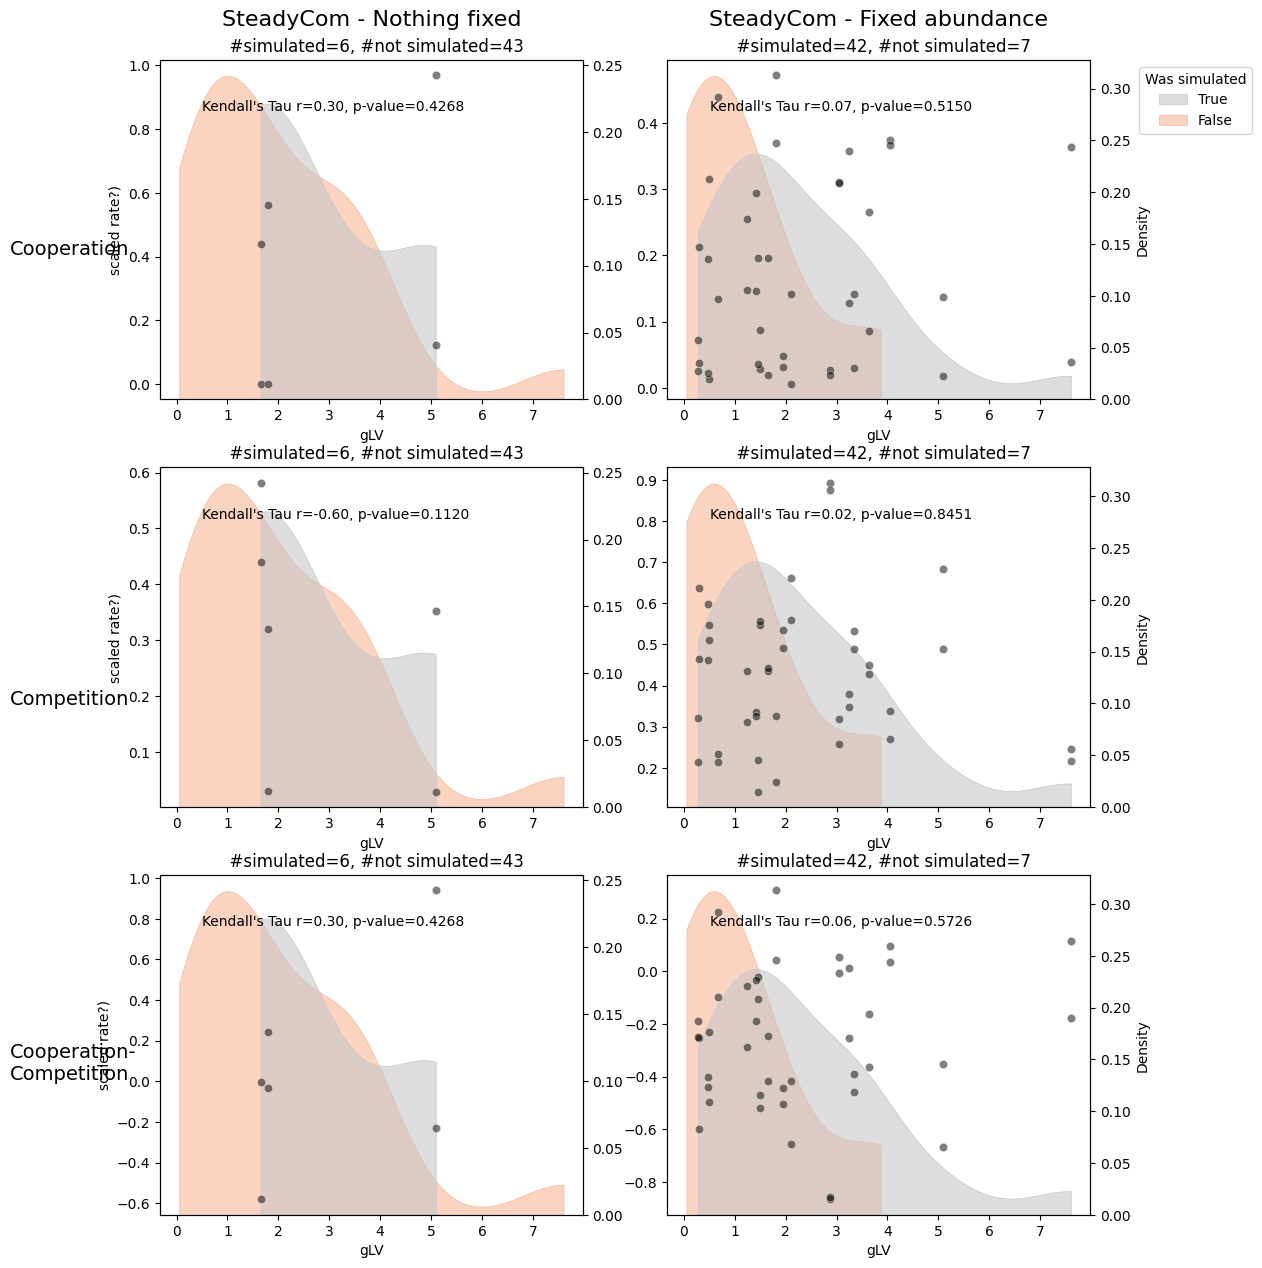

In [22]:
fig,axs,axs_twin,not_simulated = correlation.make_scatterplots_simulation_method(simulation_dict,
                                                                                 signal_exp,
                                                                                 simulation_method="steadycom",
                                                                                 metric="rate?",
                                                                                )

<Axes: xlabel='member_second'>

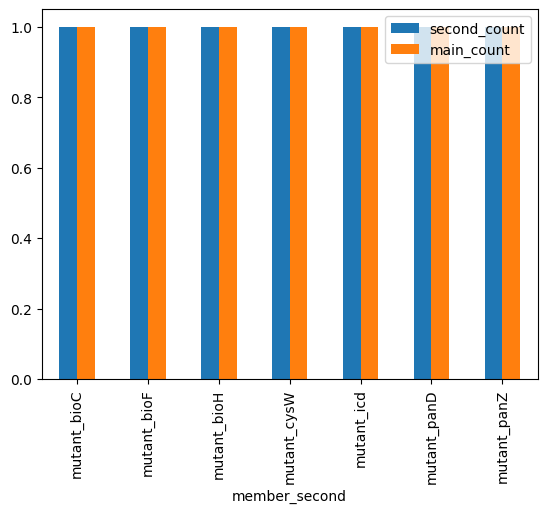

In [32]:

not_simulated_df = pd.DataFrame(not_simulated)
not_simulated_df.columns = ["member_second","member_main"]

counts = (not_simulated_df.groupby("member_second")
          .agg(second_count=("member_second","size"), main_count=("member_main","size"))
          .fillna(0)
          /9)

counts.plot(kind="bar")

## Diagnostics

In [106]:
support_df = diagnostic.identify_support(signal_exp,exp_thresh_list=[1.5])
support_df.index.names = ["role","exp_thresh"]
support_df.sort_index(ascending=False)

,,positive_support,negative_support,total,no-skill line
role,exp_thresh,,,,
coop,1.5,26,23,49,0.530612
comp,1.5,0,49,49,0.000000


In [107]:
permutation_results = diagnostic.find_pvalues_of_PR(simulation_dict=simulation_dict,
                                signal_exp=signal_exp,
                                exp_thresh_list=[1.5],
                                coop_or_comp_list=["coop"]
                              )

results_pr_auc_df_bh = permutation_results.copy()
results_pr_auc_df_bh = results_pr_auc_df_bh.join(support_df["no-skill line"])
results_pr_auc_df_bh["rank"] = results_pr_auc_df_bh["p_value"].rank()
results_pr_auc_df_bh["p-value BH critical"] = (results_pr_auc_df_bh["rank"]/results_pr_auc_df_bh.shape[0])*0.05
results_pr_auc_df_bh["pass BH test"] = results_pr_auc_df_bh["p_value"]<results_pr_auc_df_bh["p-value BH critical"]
results_pr_auc_df_bh.sort_index(level="exp_thresh").sort_values(["p-value BH critical"])

p_value  \
role simulation_method condition                              metric              exp_thresh            
coop steadiercom       SteadierCom - Fixed growth             frequency           1.5          0.0009   
     steadycom         SteadyCom - Nothing fixed              rate?               1.5          0.0167   
                       SteadyCom - Fixed abundance            rate?               1.5          0.1095   
     steadiercom       SteadierCom - Fixed growth & abundance frequency           1.5          0.2360   
                       SteadierCom - Fixed abundance          frequency*mass_rate 1.5          0.3915   
                                                              frequency           1.5          0.4140   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 1.5          0.4213   
                       SteadierCom - Fixed growth             frequency*mass_rate 1.5          0.6615   

                                                                                              observed_auc  \
role simulation_method condition                              metric              exp_thresh                 
coop steadiercom       SteadierCom - Fixed growth             frequency           1.5             0.795266   
     steadycom         SteadyCom - Nothing fixed              rate?               1.5             0.638932   
                       SteadyCom - Fixed abundance            rate?               1.5             0.652534   
     steadiercom       SteadierCom - Fixed growth & abundance frequency           1.5             0.612541   
                       SteadierCom - Fixed abundance          frequency*mass_rate 1.5             0.580217   
                                                              frequency           1.5             0.574966   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 1.5             0.572554   
                       SteadierCom - Fixed growth             frequency*mass_rate 1.5             0.530215   

                                                                                              no-skill line  \
role simulation_method condition                              metric              exp_thresh                  
coop steadiercom       SteadierCom - Fixed growth             frequency           1.5              0.530612   
     steadycom         SteadyCom - Nothing fixed              rate?               1.5              0.530612   
                       SteadyCom - Fixed abundance            rate?               1.5              0.530612   
     steadiercom       SteadierCom - Fixed growth & abundance frequency           1.5              0.530612   
                       SteadierCom - Fixed abundance          frequency*mass_rate 1.5              0.530612   
                                                              frequency           1.5              0.530612   
                       SteadierCom - Fixed growth & abundance frequency*mass_rate 1.5              0.530612   
                       SteadierCom - Fixed growth             frequency*mass_rate 1.5              0.530612   

                                                                                              rank  \
role simulation_method condition                              metric              exp_thresh         
coop steadiercom       SteadierCom - Fixed growth             frequency           1.5          1.0   
     steadycom         SteadyCom - Nothing fixed              rate?               1.5          2.0   
                       SteadyCom - Fixed abundance            rate?               1.5          3.0   
     steadiercom       SteadierCom - Fixed growth & abundance frequency           1.5          4.0   
                       SteadierCom - Fixed abundance          frequency*mass_rate 1.5          5.0   
                                                              frequency           1.5          6.0   
               

[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.
[INFO] plot_diagnostic_curve uses fillna(0) to for missing entries in simulations that exist in experimental results.


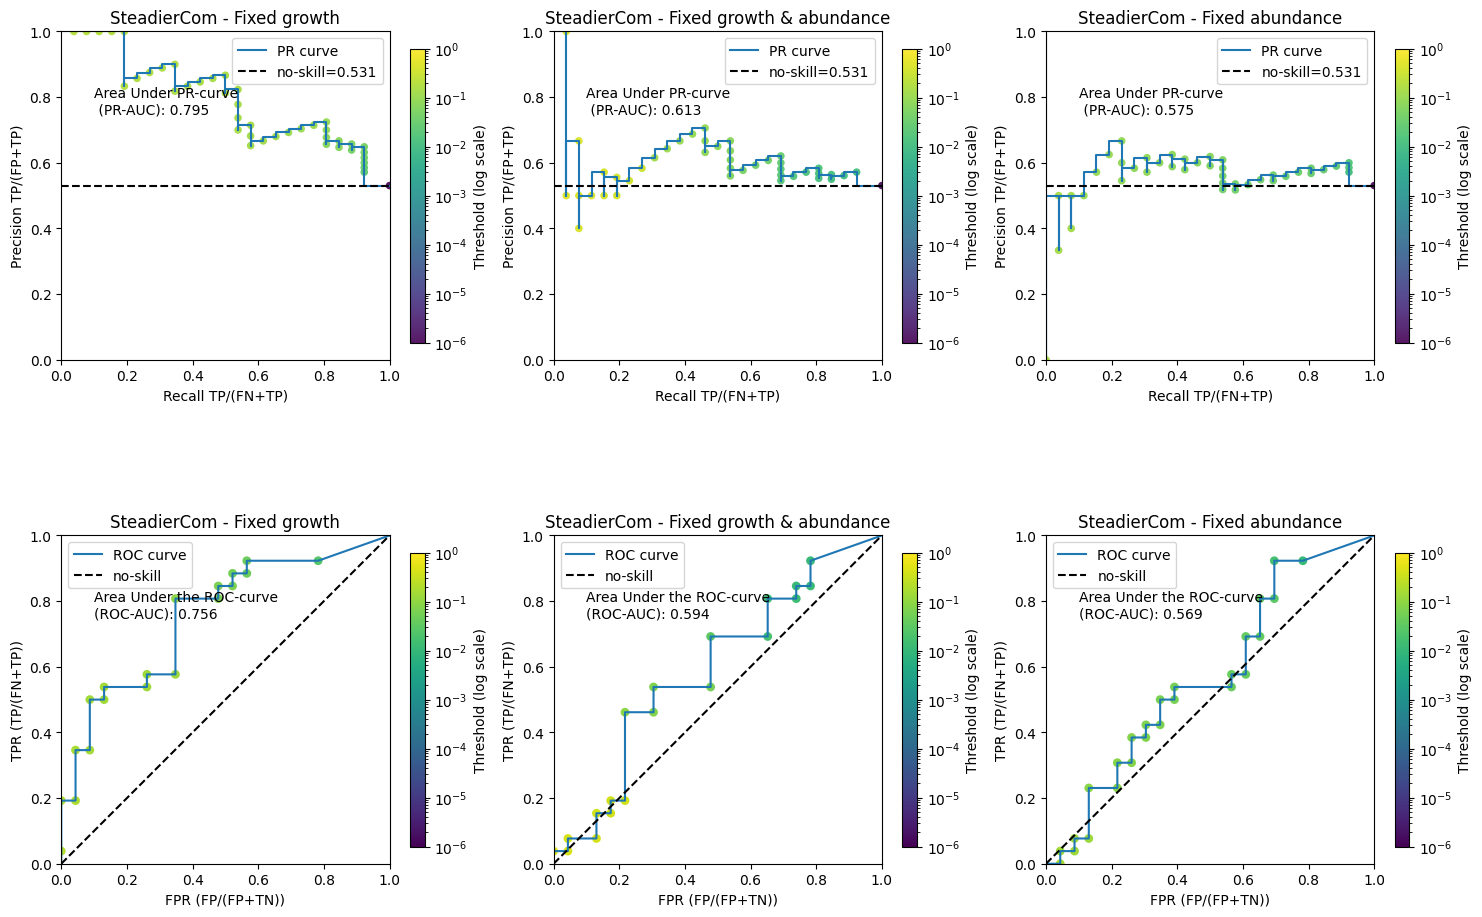

In [116]:
metric = "frequency"
names = simulation_dict["steadiercom"].keys()
fig, axs = plt.subplots(2, 3, figsize=(18, 12))
for ax_sublist, name in zip(axs.transpose(), names):

    ax1 = ax_sublist[0]
    ax2 = ax_sublist[1]
    simulated_res = simulation_dict["steadiercom"][name]
    fig,axs = diagnostic.plot_diagnostic_curve(simulated_res,
                                               signal_exp,
                                               PR_or_ROC="PR",
                                               exp_thresh=1.5,
                                                coop_or_comp="coop",
                                                metric=metric,
                                                ax=ax1,
                                                title=name,
                                                plot_cbar=True,
                                                verbose=True)
    fig,axs = diagnostic.plot_diagnostic_curve(simulated_res,
                                            signal_exp,
                                            PR_or_ROC="ROC",
                                            exp_thresh=1.5,
                                            coop_or_comp="coop",
                                            metric=metric,
                                            ax=ax2,
                                            title=name,
                                            plot_cbar=True,
                                            verbose=True)
